# Sentinel-2 NDVI time series for a polygon

Starting-point notebook: search Sentinel-2 L2A scenes on Microsoft Planetary Computer (no account needed), mask clouds with the SCL band, compute NDVI inside a polygon, and build a cleaned time series.

**Workflow**
1. Choose the AOI (`AOI_FILE`) and dates
2. Search scenes (STAC)
3. Load a lazy data cube (stackstac) and split the AOI into topographic zones (elevation band × aspect, Copernicus DEM)
4. Harmonise the 2022 processing-baseline offset
5. Mask clouds + polygon, compute NDVI
6. Download all scenes year by year and cache the per-date statistics plus cloud/quality variables per zone as CSV (skipped with `DOWNLOAD = False`)
7. Load the cached statistics, filter by the quality variables, smooth, analyse (whole AOI in 7a-7c, per zone vs topography in 7d), export

Sections 2-5 only define functions; the download happens in section 6. Once the cache is complete, set `DOWNLOAD = False` to run the analysis offline in seconds.

**Several AOIs:** set `AOI_FILE` in section 1 and run all cells. Every AOI has its own download cache (`cache/<file name>_zones`) and its own exported results (`results/<file name>`), so switching never overwrites or re-downloads another AOI's data.

In [253]:
# Run once
#!pip install pystac-client planetary-computer stackstac rioxarray geopandas rasterio scipy statsmodels matplotlib
#!pip install "folium>=0.12" matplotlib mapclassify

In [254]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import rioxarray  # noqa: F401  (registers the .rio accessor)
import rasterio
import matplotlib.pyplot as plt
import pystac_client
import planetary_computer
import stackstac
from rasterio.features import geometry_mask, shapes
from shapely.geometry import Polygon, shape

## 1. Configuration

In [255]:
DOWNLOAD = False            # False: no downloads, only load the cached per-year statistics (section 6)

# AOI: file name in AOI_FOLDER. Switch AOIs by changing AOI_FILE and running all cells.
#   None                               -> demo rectangle (next cell)
#   "field.geojson" / ".shp" / ".gpkg" -> vector polygon(s)
#   "mask.tif" / ".tiff"               -> GeoTIFF; pixels selected by "values" in AOI_RASTER_OPTIONS become the AOI
AOI_FOLDER = Path(r"C:\Users\hanna\OneDrive\Desktop\Documents\Uni\HS 26\GIS Exkursion\project")
# AOI_FILE = "Larch_Classification_2017_threshold099.tif"
AOI_FILE = "Larch_Classification_2017_multidate_aspect_improved_threshold099.tif"
# GeoTIFF only, per file: pixel values to keep (e.g. [1] or [11, 12]) and the band holding them.
# Files not listed use every valid non-zero pixel of band 1. Kept per file, so each AOI's cache stays valid.
AOI_RASTER_OPTIONS = {
    # "other_mask.tif": {"values": [1], "band": 1},
}

AOI_PATH = str(AOI_FOLDER / AOI_FILE) if AOI_FILE else None
AOI_RASTER_VALUES = AOI_RASTER_OPTIONS.get(AOI_FILE, {}).get("values")
AOI_RASTER_BAND = AOI_RASTER_OPTIONS.get(AOI_FILE, {}).get("band", 1)
AOI_NAME = Path(AOI_FILE).stem if AOI_FILE else "demo_rectangle"
# Per AOI: cache of per-date statistics per zone (one CSV per calendar year) and exported results (section 8)
CACHE_DIR = Path("cache") / f"{AOI_NAME}_zones"
OUT_DIR = Path("results") / AOI_NAME
if AOI_PATH and not Path(AOI_PATH).exists():
    found = sorted(p.name for p in AOI_FOLDER.iterdir()
                   if p.suffix.lower() in {".tif", ".tiff", ".geojson", ".shp", ".gpkg"})
    raise FileNotFoundError(f"{AOI_PATH} not found. AOI files in {AOI_FOLDER}: {found}")
print(f"AOI: {AOI_NAME} | cache: {CACHE_DIR} | results: {OUT_DIR}")
START, END = "2017-01-01", "2023-12-31"
# Date filters, applied when loading the cache (all scenes are downloaded, so these can change freely)
MAX_SCENE_CLOUD = 100       # max % cloud cover of the whole tile (eo:cloud_cover; coarse, 100 = no limit)
MIN_VALID_FRACTION = 0.15   # share of clear pixels inside the polygon required to keep a date
# Max share of polygon pixels per SCL class group (groups defined in section 5); 1.0 = no limit
MAX_SCL_FRACTION = {"cloud": 1.0, "cirrus": 1.0, "shadow": 1.0, "snow": 1.0, "nodata": 1.0}
SCL_KEEP = [4,5]          # 4 = vegetation, 5 = bare soil (add 6 for water if relevant)
RESOLUTION = 10            # metres
INNER_BUFFER = 0           # metres; shrink polygon to avoid mixed edge pixels (0 to disable)

# Topographic zones (section 3): AOI pixels split into elevation bands x north/south facing (+ flat)
DEM_COLLECTION = "cop-dem-glo-30"   # Copernicus DEM GLO-30 on Planetary Computer
ELEV_STEP = 200          # m, elevation band width
FLAT_SLOPE = 5           # degrees; flatter pixels get aspect "flat"
MIN_ZONE_PIXELS = 200    # zones with fewer AOI pixels are dropped (still counted in "all")

In [256]:
def aoi_from_geotiff(path, values=None, band=1):
    # Vectorise the selected pixels so the rest of the notebook can treat them like a polygon
    with rasterio.open(path) as src:
        data = src.read(band, masked=True)
        transform, crs = src.transform, src.crs
    if crs is None:
        raise ValueError(f"{path} has no CRS; assign one (e.g. with gdal_edit.py -a_srs) first")
    valid = ~np.ma.getmaskarray(data) & np.isfinite(data.data)
    keep = valid & (np.isin(data.data, values) if values is not None else data.data != 0)
    if not keep.any():
        raise ValueError(f"No pixels in {path} match AOI_RASTER_VALUES={values}")
    geoms = [shape(g) for g, _ in shapes(keep.astype("uint8"), mask=keep, transform=transform)]
    print(f"{int(keep.sum())} raster pixels -> {len(geoms)} polygon part(s)")
    return gpd.GeoDataFrame(geometry=geoms, crs=crs)

if AOI_PATH is None:
    # Demo: small forest patch inside the Swiss National Park
    # Approximate forested area in the park near Zernez / Val Mustair (lon, lat)
    aoi = gpd.GeoDataFrame(geometry=[Polygon([
            (10.18, 46.62), (10.23, 46.62), (10.23, 46.66), (10.18, 46.66)
        ])], crs=4326)
elif str(AOI_PATH).lower().endswith((".tif", ".tiff")):
    aoi = aoi_from_geotiff(AOI_PATH, AOI_RASTER_VALUES, AOI_RASTER_BAND)
else:
    aoi = gpd.read_file(AOI_PATH)

aoi = aoi.dissolve()
aoi_wgs84 = aoi.to_crs(4326)

# Use a background map without requiring a CartoDB API key.
# This keeps the earlier look while avoiding the warning.
map_ = aoi.explore(
    color="darkgreen",
    fill=False,
    linewidth=2,
    tiles="OpenStreetMap",
    tooltip=False,
 )
map_

45746 raster pixels -> 2407 polygon part(s)


## 2. Search Sentinel-2 L2A scenes

Planetary Computer signed URLs expire after roughly an hour, so section 6 searches again right before each year's download. All scenes are returned regardless of cloud cover; the tile cloud cover is stored per date and filtered when loading.

In [257]:
def search_scenes(start, end):
    catalog = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=planetary_computer.sign_inplace,
    )
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        # Convex hull keeps the request small; a GeoTIFF mask dissolves into thousands of pixel outlines
        intersects=aoi_wgs84.geometry.iloc[0].convex_hull,
        datetime=f"{start}/{end}",
    )
    return search.item_collection()

## 3. Build a lazy data cube

Nothing is downloaded yet; data is read only for the polygon's extent when computed.

In [258]:
def item_epsg(item):
    p = item.properties
    if "proj:epsg" in p and p["proj:epsg"]:
        return int(p["proj:epsg"])
    return int(str(p["proj:code"]).split(":")[-1])

def build_cube(items):
    # Use the most common UTM zone among the scenes; others get reprojected.
    # Convert NumPy scalars to a plain Python int so stackstac doesn't hit the out_epsg assertion.
    epsg = int(pd.Series([item_epsg(i) for i in items]).mode()[0])
    aoi_utm = aoi.to_crs(epsg)
    if INNER_BUFFER:
        aoi_utm = aoi_utm.buffer(-INNER_BUFFER).to_frame("geometry")

    ds = stackstac.stack(
        items,
        assets=["B02", "B03", "B04", "B06", "B08", "SCL"], # blue, green, red, red-edge 2 (20 m), nir, and SCL for cloud masking
        resolution=RESOLUTION,
        epsg=epsg,
        bounds_latlon=tuple(aoi_wgs84.total_bounds),
        resampling=0,           # nearest neighbour (important for the SCL class band)
        chunksize=1024,
        xy_coords="center",    # coords = pixel centres, as rioxarray assumes (default is top-left -> 5 m shifted mask)
    )
    return ds.rio.write_crs(epsg), aoi_utm

### Topographic zones

The AOI pixels are split into **zones: `ELEV_STEP` elevation bands × north / south facing**, plus "flat" for slopes under `FLAT_SLOPE`. Elevation comes from the Copernicus DEM GLO-30. Slope and aspect are computed at 30 m and resampled bilinearly to the 10 m Sentinel-2 grid. Aspect is carried as northness = cos(aspect) and eastness = sin(aspect), so 359° and 1° are not averaged to 180°. A pixel is north facing if northness ≥ 0 (aspect W through N to E), otherwise south facing.

Zones with fewer than `MIN_ZONE_PIXELS` pixels are dropped. The `"all"` zone is always the whole AOI, so its statistics are the same as without zones.

In [ ]:
from rasterio.enums import Resampling
from rasterio.warp import transform_bounds
from rioxarray.exceptions import NoDataInBounds, OneDimensionalRaster
from rioxarray.merge import merge_arrays

ASPECT_CODES = {"N": 0, "S": 1, "flat": 2}   # aspect classes as stored in zones.tif
ASPECT_COLORS = {"N": "tab:blue", "S": "tab:orange", "flat": "grey"}
ZONE_NODATA = -9999

def dem_30m(epsg, bounds):
    # Copernicus DEM tiles covering bounds (x0, y0, x1, y1 in epsg), mosaicked and reprojected to epsg at 30 m
    catalog = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=planetary_computer.sign_inplace,
    )
    lonlat = transform_bounds(f"EPSG:{epsg}", "EPSG:4326", *bounds)
    tiles = []
    for item in catalog.search(collections=[DEM_COLLECTION], bbox=lonlat).item_collection():
        tile = rioxarray.open_rasterio(item.assets["data"].href, masked=True).squeeze("band", drop=True)
        try:
            tiles.append(tile.rio.clip_box(*lonlat, crs="EPSG:4326"))
        except (NoDataInBounds, OneDimensionalRaster):   # tile only touches the box
            pass
    if not tiles:
        raise ValueError(f"No {DEM_COLLECTION} tiles over the AOI")
    dem = merge_arrays(tiles) if len(tiles) > 1 else tiles[0]
    return dem.rio.reproject(f"EPSG:{epsg}", resolution=30, resampling=Resampling.bilinear)

def zone_layers(ds, inside):
    # Elevation band and aspect class of every AOI pixel on the cube grid.
    # Returns the zone masks {"all": inside, "1800_N": ..., ...}, a zone table and a raster for zones.tif.
    epsg = ds.rio.crs.to_epsg()
    x0, y0, x1, y1 = ds.rio.bounds()
    dem = dem_30m(epsg, (x0 - 100, y0 - 100, x1 + 100, y1 + 100))   # padded, so slope is defined at the edges

    # Slope and aspect at 30 m. Passing the coordinates gives gradients in m/m and handles the descending y axis.
    z = dem.values.astype("float64")
    dz_dy, dz_dx = np.gradient(z, dem.y.values, dem.x.values)
    grad = np.hypot(dz_dx, dz_dy)
    # Aspect = compass direction of steepest descent (0 = N, 90 = E), kept as northness = cos(aspect)
    # and eastness = sin(aspect)
    with np.errstate(invalid="ignore", divide="ignore"):
        northness, eastness = -dz_dy / grad, -dz_dx / grad
    flat = grad == 0
    northness[flat] = eastness[flat] = 0
    layers = xr.Dataset({
        name: dem.copy(data=v.astype("float32")).rio.write_nodata(np.nan, encoded=False)
        for name, v in {"elevation": z, "slope": np.degrees(np.arctan(grad)),
                        "northness": northness, "eastness": eastness}.items()})

    # Bilinear onto the 10 m grid of the cube
    grid = layers.rio.reproject_match(ds.isel(time=0, band=0, drop=True), resampling=Resampling.bilinear)
    grid = grid.assign_coords(x=ds.x, y=ds.y)

    has_dem = inside & grid.elevation.notnull() & grid.slope.notnull()
    elev_band = np.floor(grid.elevation / ELEV_STEP) * ELEV_STEP
    aspect = xr.where(grid.slope < FLAT_SLOPE, ASPECT_CODES["flat"],
                      xr.where(grid.northness >= 0, ASPECT_CODES["N"], ASPECT_CODES["S"]))

    def summary(zone, mask, band, asp):
        means = {f"{short}_mean": float(grid[var].where(mask).mean())
                 for short, var in [("elev", "elevation"), ("slope", "slope"),
                                    ("northness", "northness"), ("eastness", "eastness")]}
        return {"zone": zone, "elev_band": band, "aspect": asp, "n_pixels": int(mask.sum()), **means}

    zones, rows = {"all": inside}, [summary("all", inside, np.nan, "all")]
    zone_id = xr.full_like(elev_band, ZONE_NODATA)   # row number in the zone table; nodata = only in "all"
    for band in np.unique(elev_band.values[has_dem.values]):
        for asp, code in ASPECT_CODES.items():
            mask = has_dem & (elev_band == band) & (aspect == code)
            if int(mask.sum()) >= MIN_ZONE_PIXELS:
                zone = f"{int(band)}_{asp}"
                zone_id = zone_id.where(~mask, len(rows))
                zones[zone] = mask
                rows.append(summary(zone, mask, int(band), asp))
    zone_table = pd.DataFrame(rows).set_index("zone")
    n_inside, n_kept = int(inside.sum()), int(zone_table.n_pixels.iloc[1:].sum())
    print(f"  {len(zones) - 1} zones with >= {MIN_ZONE_PIXELS} pixels; {n_inside - n_kept} of {n_inside} "
          "AOI pixels are only in 'all' (small zone or no DEM)")

    # zones.tif bands: elevation (whole extent), elevation band, aspect class, zone row (AOI pixels only)
    zone_raster = (xr.concat([grid.elevation.round(), elev_band.where(has_dem), aspect.where(has_dem), zone_id],
                             dim="band")
                   .fillna(ZONE_NODATA).astype("int16").assign_coords(band=[1, 2, 3, 4])
                   .rio.write_nodata(ZONE_NODATA).rio.write_crs(epsg))
    zone_raster.attrs["long_name"] = ("elevation", "elev_band", "aspect", "zone_id")
    return zones, zone_table, zone_raster

## 4. Harmonise the processing-baseline offset

Since 25 Jan 2022 (baseline 04.00), L2A reflectances carry a +1000 offset. The Planetary Computer collection is **not** harmonised, so we subtract it from post-2022 scenes; otherwise the NDVI series shows an artificial jump.

In [259]:
CUTOFF = np.datetime64("2022-01-25")

def harmonised_bands(ds):
    offset = xr.where(ds.time >= CUTOFF, 1000, 0)
    bands = {name: (ds.sel(band=b) - offset).clip(min=0)
             for name, b in [("blue", "B02"), ("green", "B03"), ("red", "B04"), ("red_edge", "B06"), ("nir", "B08")]}
    bands["scl"] = ds.sel(band="SCL")
    return bands

## 5. Cloud mask, polygon mask, NDVI

In [260]:
# SCL class groups whose share of the polygon is stored per date (for filtering after loading)
SCL_GROUPS = {
    "nodata": [0, 1],         # no data / saturated or defective
    "dark": [2],              # dark area pixels (incl. topographic shadow)
    "shadow": [3],            # cloud shadow
    "water": [6],
    "unclassified": [7],
    "cloud": [8, 9],          # cloud medium / high probability
    "cirrus": [10],           # thin cirrus
    "snow": [11],             # snow / ice
}

def polygon_mask(ds, aoi_utm):
    # Polygon mask on the data grid (True = inside polygon)
    inside = ~geometry_mask(
        aoi_utm.geometry,
        out_shape=(ds.sizes["y"], ds.sizes["x"]),
        transform=ds.rio.transform(),
        all_touched=False,
    )
    return xr.DataArray(inside, dims=("y", "x"), coords={"y": ds.y, "x": ds.x})

def index_cube(num, den, valid):
    # Lazy ratio num / den on clear pixels inside the polygon; zero denominators become NaN.
    num, den = num.where(valid), den.where(valid)
    idx = (num / den).where(den != 0)
    # Same date can appear twice (overlapping tiles/orbits) -> merge per day
    idx = idx.groupby(idx.time.dt.floor("D")).mean(skipna=True).rename(floor="time")
    # One chunk per date covering the whole grid, so the spatial median works on the lazy cube
    return idx.chunk({"time": 1, "y": -1, "x": -1})

def index_cubes(ds, mask):
    # Index cubes on clear pixels inside mask (the AOI); zones are selected later with .where(zone_mask)
    b = harmonised_bands(ds)
    valid = b["scl"].isin(SCL_KEEP) & mask
    cubes = {
        # NDVI = (NIR - RED) / (NIR + RED)
        "ndvi": index_cube(b["nir"] - b["red"], b["nir"] + b["red"], valid),
        # GRVI (Green-Red Vegetation Index) from green and red reflectance: (B03 - B04) / (B03 + B04)
        "grvi": index_cube(b["green"] - b["red"], b["green"] + b["red"], valid),
        # PSRI (Plant Senescence Reflectance Index): (B04 - B02) / B06, rises as leaves/needles yellow
        "psri": index_cube(b["red"] - b["blue"], b["red_edge"], valid),
    }
    return cubes

def scl_fractions(scl, zones, n_pixels):
    # Share of each zone's pixels per SCL class group and date, keyed by (zone, column). Same-day scenes
    # (overlapping tiles) are merged: a pixel counts for a class if any scene shows it, but as nodata only
    # if no scene has data there. The merge is per pixel, so it is done once and then masked per zone.
    day = scl.time.dt.floor("D")
    out = {}
    for group, classes in SCL_GROUPS.items():
        if group == "nodata":
            hit = (scl.isin(classes) | scl.isnull()).astype("uint8").groupby(day).min()
        else:
            hit = scl.isin(classes).astype("uint8").groupby(day).max()
        hit = hit.rename(floor="time")
        for zone, mask in zones.items():
            out[(zone, f"scl_{group}_fraction")] = hit.where(mask, 0).sum(["x", "y"]) / n_pixels[zone]
    return out

## 6. Download per year, cache per-date statistics, quality filter

With `DOWNLOAD = True`, every calendar year from `START` to `END` gets its own search (fresh signed URLs), download and `stats_<year>.csv` in `CACHE_DIR`. The statistics are computed for every topographic zone (section 3) in the same pass, so each band is still downloaded only once. The CSV is in long format: one row per date and zone (column `zone`, `"all"` = whole AOI). The first downloaded year also writes `zones.csv` (pixel count, mean elevation/slope/northness/eastness per zone) and `zones.tif` (elevation, elevation band, aspect class and zone row per pixel). Years that already have a CSV are skipped, so after an error just re-run the cell. A year that is still running (e.g. the current one) is cached as far as it goes; delete its CSV to fetch newer scenes.

Every scene is downloaded, whatever its cloud cover. Besides the index statistics, each date gets quality variables:
- `scene_cloud_cover`: tile cloud cover in % (`eo:cloud_cover`, max over same-day tiles)
- `scl_<group>_fraction`: share of the zone's pixels in each SCL class group (`SCL_GROUPS`, section 5)
- `<index>_valid_fraction`: share of the zone's pixels that are clear (`SCL_KEEP`) and give a valid index value

The quality filter is applied per date and zone. `df`, `df_clean` etc. are the `"all"` zone. `clean_by_zone[index][zone]` holds the cleaned median series of every zone.

The cache is only valid for the AOI, masking and zone settings it was built with (stored in `settings.json`); the cell refuses to mix caches. `START`/`END`, `MAX_SCENE_CLOUD`, `MAX_SCL_FRACTION` and `MIN_VALID_FRACTION` are applied when loading, so they can change freely.

In [261]:
import dask
from dask.diagnostics import ProgressBar

DASK_WORKERS = 8   # parallel reads; lower it if memory runs short, raise it on a fast connection

# Settings that change the cached numbers
cache_settings = {
    "aoi_path": str(AOI_PATH), "aoi_raster_values": AOI_RASTER_VALUES, "aoi_raster_band": AOI_RASTER_BAND,
    "scl_keep": SCL_KEEP, "scl_groups": SCL_GROUPS, "resolution": RESOLUTION, "inner_buffer": INNER_BUFFER,
    "all_scenes": True,  # no cloud pre-filter at search time
    "dem": DEM_COLLECTION, "elev_step": ELEV_STEP, "flat_slope": FLAT_SLOPE, "min_zone_pixels": MIN_ZONE_PIXELS,
}
settings_file = CACHE_DIR / "settings.json"
if settings_file.exists():
    cached_settings = json.loads(settings_file.read_text())
    if cached_settings != cache_settings:
        raise ValueError(f"{CACHE_DIR} was built with different settings:\n{cached_settings}\n"
                         "Change CACHE_DIR or delete that folder to rebuild it.")
elif DOWNLOAD:
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    settings_file.write_text(json.dumps(cache_settings, indent=1))
else:
    raise FileNotFoundError(f"No cache in {CACHE_DIR}; run once with DOWNLOAD = True")

def date_stats(cube, n_inside):
    return {
        "mean": cube.mean(["x", "y"]),
        "median": cube.median(["x", "y"]),
        "std": cube.std(["x", "y"]),
        "valid_fraction": cube.notnull().sum(["x", "y"]) / n_inside,
    }

def save_zone_info(zone_table, zone_raster, year):
    # zones.csv / zones.tif come from the first downloaded year; later years should give the same zones
    table_file = CACHE_DIR / "zones.csv"
    if not table_file.exists():
        zone_table.to_csv(table_file)
        zone_raster.rio.to_raster(CACHE_DIR / "zones.tif", compress="deflate")
    elif not pd.read_csv(table_file, index_col="zone").n_pixels.equals(zone_table.n_pixels):
        warnings.warn(f"{year}: zone pixel counts differ from {table_file} (different UTM zone/grid?)")

def year_stats(year):
    items = search_scenes(f"{year}-01-01", f"{year}-12-31")
    if len(items) == 0:
        print("  no scenes")
        return pd.DataFrame(columns=["zone"], index=pd.DatetimeIndex([], name="date"))
    ds, aoi_utm = build_cube(items)
    inside = polygon_mask(ds, aoi_utm)
    print(f"  {len(items)} scenes, {int(inside.sum())} pixels inside the polygon")
    zones, zone_table, zone_raster = zone_layers(ds, inside)
    save_zone_info(zone_table, zone_raster, year)
    cubes = index_cubes(ds, inside)
    lazy = {}
    for zone, mask in zones.items():
        for name, cube in cubes.items():
            for stat, v in date_stats(cube.where(mask), zone_table.n_pixels[zone]).items():
                lazy[(zone, f"{name}_{stat}")] = v
    lazy.update(scl_fractions(ds.sel(band="SCL"), zones, zone_table.n_pixels))
    # One compute for all indices and zones: each band of each scene is downloaded once and shared,
    # and only the per-date statistics are kept in memory (not the full per-pixel cubes).
    with ProgressBar(), dask.config.set(num_workers=DASK_WORKERS), warnings.catch_warnings():
        # Fully cloudy dates have no valid pixel: their statistics become NaN (valid_fraction 0, filtered below)
        warnings.simplefilter("ignore", RuntimeWarning)
        (stats,) = dask.compute(lazy)
    dates = pd.to_datetime(cubes["ndvi"].time.values)
    # Tile cloud cover per date (max over same-day tiles)
    item_days = pd.to_datetime([i.datetime for i in items], utc=True).tz_convert(None).floor("D")
    cover = pd.Series([i.properties.get("eo:cloud_cover", np.nan) for i in items], index=item_days)
    cover = cover.groupby(level=0).max().reindex(dates).values
    parts = []
    for zone in zones:
        part = pd.DataFrame({col: v.values for (z, col), v in stats.items() if z == zone}, index=dates)
        part.insert(0, "scene_cloud_cover", cover)
        part.insert(0, "zone", zone)
        parts.append(part)
    frame = pd.concat(parts).sort_index(kind="stable")
    frame.index.name = "date"
    return frame

years = range(pd.Timestamp(START).year, min(pd.Timestamp(END), pd.Timestamp.today()).year + 1)
if DOWNLOAD:
    failed = []
    for year in years:
        path = CACHE_DIR / f"stats_{year}.csv"
        if path.exists():
            continue
        print(f"{year}:")
        try:
            year_stats(year).to_csv(path)
        except Exception as e:  # e.g. server hiccup; the year stays uncached and is retried on the next run
            failed.append(year)
            print(f"  failed: {e!r}")
    if failed:
        print(f"Failed years {failed}: re-run this cell to retry them")

# Load the cache (long format: one row per date and zone)
missing = [y for y in years if not (CACHE_DIR / f"stats_{y}.csv").exists()]
if missing:
    print(f"Not cached yet: {missing}")
frames = [pd.read_csv(f, index_col="date", parse_dates=["date"]) for f in sorted(CACHE_DIR.glob("stats_*.csv"))]
stats_all = pd.concat([f for f in frames if not f.empty]).sort_index(kind="stable").loc[START:END]
zone_table = pd.read_csv(CACHE_DIR / "zones.csv", index_col="zone")
ZONES = list(zone_table.index)   # "all" first, then elevation band x aspect

QUALITY_COLS = ["scene_cloud_cover"] + [f"scl_{g}_fraction" for g in SCL_GROUPS]

def index_frame(name, zone="all"):
    cols = [f"{name}_mean", f"{name}_median", f"{name}_std", f"{name}_valid_fraction"]
    rows = stats_all[stats_all.zone == zone]
    return rows[cols + QUALITY_COLS].rename(columns={f"{name}_valid_fraction": "valid_fraction"})

def quality_ok(frame):
    # Date-level quality filter (tile cloud cover and SCL shares of the zone's pixels), shared by all indices
    ok = frame.scene_cloud_cover <= MAX_SCENE_CLOUD
    for group, limit in MAX_SCL_FRACTION.items():
        ok &= frame[f"scl_{group}_fraction"] <= limit
    return ok

def clean_frame(name, zone="all"):
    frame = index_frame(name, zone)
    return frame[quality_ok(frame) & (frame.valid_fraction >= MIN_VALID_FRACTION)].copy()

df = index_frame("ndvi")
df_grvi = index_frame("grvi")
df_psri = index_frame("psri")
print(f"{int(quality_ok(df).sum())} of {len(df)} dates pass MAX_SCENE_CLOUD and MAX_SCL_FRACTION")

df_clean = clean_frame("ndvi")
df_grvi_clean = clean_frame("grvi")
df_psri_clean = clean_frame("psri")
print(f"{len(df_clean)} of {len(df)} NDVI dates kept")
print(f"{len(df_grvi_clean)} of {len(df_grvi)} GRVI dates kept")
print(f"{len(df_psri_clean)} of {len(df_psri)} PSRI dates kept")

# Cleaned median series per index and zone, for the zone analysis (7a, 7b, 7d)
clean_by_zone = {name.upper(): {zone: clean_frame(name, zone)[f"{name}_median"] for zone in ZONES}
                 for name in ["ndvi", "grvi", "psri"]}
print("Zones and clear dates kept per index:")
display(zone_table[["n_pixels", "elev_mean", "slope_mean", "northness_mean"]].round(2).join(
    pd.DataFrame({name: {z: len(s) for z, s in by_zone.items()} for name, by_zone in clean_by_zone.items()})
      .add_prefix("dates_")))
print("NDVI sample:")
df_clean.head()
print("GRVI sample:")
df_grvi_clean.head()

940 of 940 dates pass MAX_SCENE_CLOUD and MAX_SCL_FRACTION
221 of 940 NDVI dates kept
221 of 940 GRVI dates kept
221 of 940 PSRI dates kept
NDVI sample:
GRVI sample:


,grvi_mean,grvi_median,grvi_std,valid_fraction,scene_cloud_cover,scl_nodata_fraction,scl_dark_fraction,scl_shadow_fraction,scl_water_fraction,scl_unclassified_fraction,scl_cloud_fraction,scl_cirrus_fraction,scl_snow_fraction
date,,,,,,,,,,,,,
2017-05-17,-0.014755,-0.012483,0.118208,0.520330,7.296805,0.000000,0.195427,0.002711,0.000000,0.151270,0.002011,0.0,0.128252
2017-05-27,0.036877,0.031974,0.121956,0.981660,4.622268,0.000000,0.006099,0.000000,0.000000,0.011695,0.000175,0.0,0.000372
2017-06-03,0.184079,0.190184,0.120821,0.174070,67.667524,0.703624,0.001858,0.015936,0.000000,0.005968,0.098522,0.0,0.000022
2017-06-06,0.264352,0.249110,0.267075,0.167097,83.856073,0.000000,0.021619,0.129935,0.000219,0.116098,0.565033,0.0,0.000000
2017-06-13,0.046971,0.055774,0.088838,0.227102,14.205620,0.737704,0.000000,0.000000,0.000000,0.034998,0.000197,0.0,0.000000


### Quick look: topographic zones and NDVI map on the clearest date

The zone map reads `zones.tif` from the cache, so it also runs with `DOWNLOAD = False`. The hillshade is lit from the south, so north-facing slopes appear dark: blue (N) pixels should sit on the dark side of the valleys. The NDVI map downloads its single date again, so it is skipped with `DOWNLOAD = False`.

In [262]:
from matplotlib.colors import LightSource

zone_file = CACHE_DIR / "zones.tif"
if zone_file.exists():
    zr = rioxarray.open_rasterio(zone_file, masked=True)
    elev, elev_band, aspect = (zr.sel(band=b).values for b in (1, 2, 3))
    on = ~np.isnan(elev_band)
    yy, xx = np.meshgrid(zr.y.values, zr.x.values, indexing="ij")
    left, bottom, right, top = zr.rio.bounds()
    shade = LightSource(azdeg=180, altdeg=30).hillshade(np.nan_to_num(elev, nan=np.nanmean(elev)),
                                                       dx=RESOLUTION, dy=RESOLUTION)
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
    for ax in axes:
        ax.imshow(shade, cmap="gray", extent=(left, right, bottom, top), alpha=0.6)
    bands = np.unique(elev_band[on])
    for b, color in zip(bands, plt.get_cmap("viridis")(np.linspace(0, 1, len(bands)))):
        sel = on & (elev_band == b)
        axes[0].scatter(xx[sel], yy[sel], s=0.2, color=color, label=f"{int(b)}-{int(b + ELEV_STEP)} m")
    for asp, code in ASPECT_CODES.items():
        sel = on & (aspect == code)
        axes[1].scatter(xx[sel], yy[sel], s=0.2, color=ASPECT_COLORS[asp], label=f"{asp} ({int(sel.sum())} px)")
    for ax, title in zip(axes, ["Elevation band of the AOI pixels", "Aspect class (hillshade lit from the south)"]):
        ax.set_title(title)
        ax.set_aspect("equal")
        ax.legend(markerscale=20, fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()
else:
    print(f"No {zone_file} yet (written with the first downloaded year)")

if DOWNLOAD:
    best = df.valid_fraction.idxmax()
    ds_best, aoi_utm_best = build_cube(search_scenes(best.date(), best.date()))
    cubes_best = index_cubes(ds_best, polygon_mask(ds_best, aoi_utm_best))
    cubes_best["ndvi"].sel(time=best).compute().plot(cmap="RdYlGn", vmin=0, vmax=1, figsize=(6, 5))
    aoi_utm_best.boundary.plot(ax=plt.gca(), color="black", linewidth=1)
    plt.title(f"NDVI {best.date()}")
    plt.show()
else:
    print("NDVI quick look skipped (DOWNLOAD = False)")

Quick look skipped (DOWNLOAD = False)


## 7. Composite and smooth

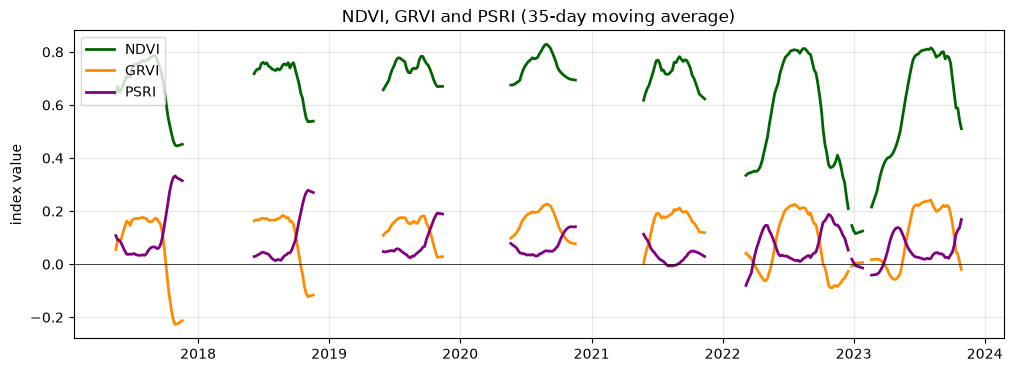

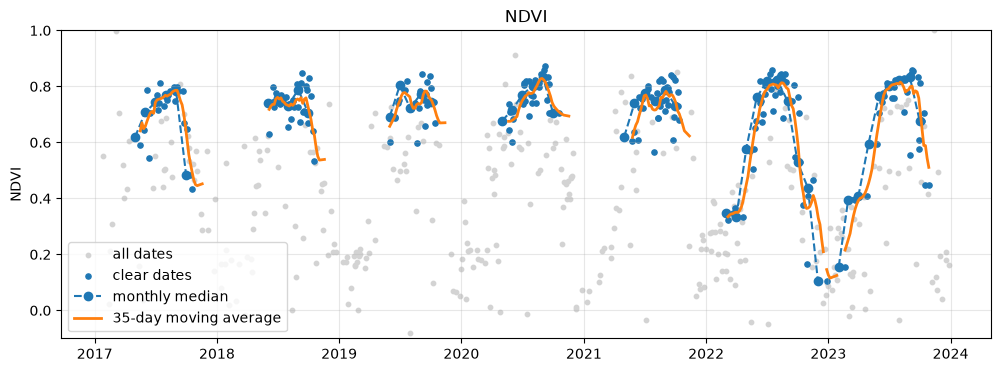

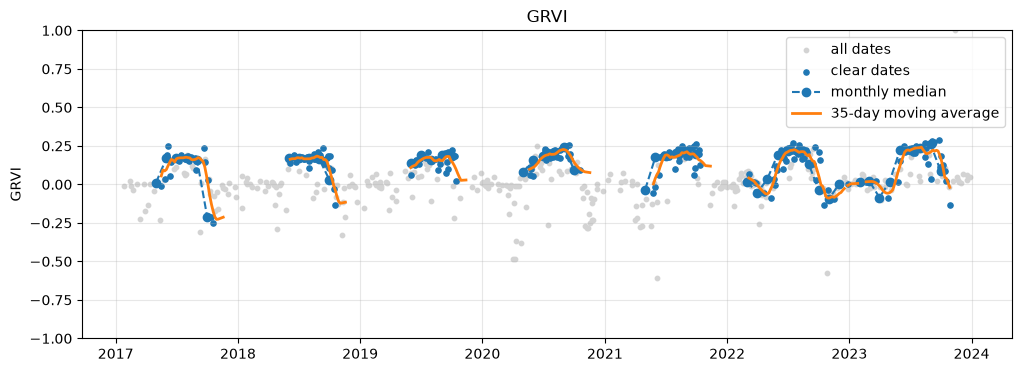

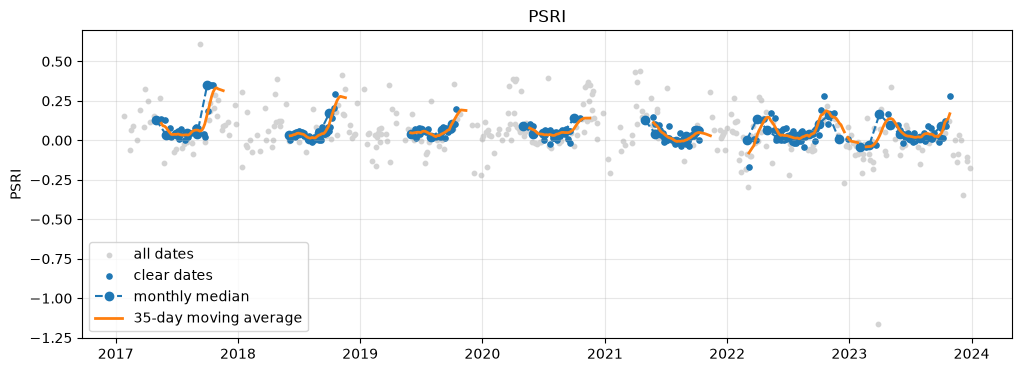

In [263]:
# Monthly median composite
monthly = df_clean["ndvi_median"].resample("MS").median()
monthly_grvi = df_grvi_clean["grvi_median"].resample("MS").median()
monthly_psri = df_psri_clean["psri_median"].resample("MS").median()

# Rolling-mean smoothing on a regular 5-day grid (interpolating gaps)
SMOOTH_WINDOW = 7   # 5-day steps, i.e. a centred 35-day moving average

def smooth(series):
    regular = (series.resample("5D").mean()
                     .interpolate(method="time", limit=6))
    rolled = regular.rolling(SMOOTH_WINDOW, center=True, min_periods=3).mean()
    return rolled.where(regular.notna())

smooth_ndvi = smooth(df_clean["ndvi_median"])
smooth_grvi = smooth(df_grvi_clean["grvi_median"])
smooth_psri = smooth(df_psri_clean["psri_median"])

# One plot with all three smoothed indices
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(smooth_ndvi.index, smooth_ndvi, lw=2, color="darkgreen", label="NDVI")
ax.plot(smooth_grvi.index, smooth_grvi, lw=2, color="darkorange", label="GRVI")
ax.plot(smooth_psri.index, smooth_psri, lw=2, color="purple", label="PSRI")
ax.axhline(0, color="black", lw=0.5)
ax.set_ylabel("index value")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
ax.set_title(f"NDVI, GRVI and PSRI ({SMOOTH_WINDOW * 5}-day moving average)")
plt.show()

# One plot per index
panels = [
    ("NDVI", df.ndvi_median, df_clean.ndvi_median, monthly, smooth_ndvi, (-0.1, 1)),
    ("GRVI", df_grvi.grvi_median, df_grvi_clean.grvi_median, monthly_grvi, smooth_grvi, (-1, 1)),
    ("PSRI", df_psri.psri_median, df_psri_clean.psri_median, monthly_psri, smooth_psri, None),
]
for name, all_dates, clear, monthly_comp, smoothed, ylim in panels:
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.scatter(all_dates.index, all_dates, s=10, c="lightgrey", label="all dates")
    ax.scatter(clear.index, clear, s=14, label="clear dates")
    ax.plot(monthly_comp.index, monthly_comp, "o--", label="monthly median")
    ax.plot(smoothed.index, smoothed, lw=2, label=f"{SMOOTH_WINDOW * 5}-day moving average")
    ax.set_ylabel(name)
    if ylim:
        ax.set_ylim(*ylim)
    ax.legend(); ax.grid(alpha=0.3)
    ax.set_title(name)
    plt.show()


## 7a. End of season (EOS) per year by NDVI

For every calendar year, EOS is taken from the smoothed NDVI curve as the first date after that year's peak where NDVI drops to
- **fixed**: 0.5, or
- **midpoint**: halfway between the year's peak and the minimum after the peak (50 % of the descending amplitude).

Years with too few valid points, or where the curve never crosses the threshold (e.g. snow gaps hide the autumn decline), get no EOS (NaN). The trend line is a linear fit of EOS day-of-year against year. The slope is in days per year (positive means the season ends later).

EOS is computed for every zone (`eos_table` is indexed by zone and year). The table, the plot and the trend/projection below use the whole AOI (`eos_all`, zone `"all"`). The zones are compared in 7d.

,n_points,peak_date,peak_ndvi,midpoint_threshold,eos_fixed_date,eos_fixed_doy,eos_mid_date,eos_mid_doy
year,,,,,,,,
2017,38,2017-08-30,0.786,0.616,2017-10-19,292.0,2017-10-04,277
2018,34,2018-07-01,0.761,0.649,None,NaN,2018-10-14,287
2019,34,2019-09-14,0.783,0.726,None,NaN,2019-10-14,287
2020,37,2020-08-29,0.828,0.761,None,NaN,2020-09-28,272
2021,35,2021-09-03,0.782,0.703,None,NaN,2021-10-13,286
2022,59,2022-08-14,0.813,0.479,2022-10-13,286.0,2022-10-13,286
2023,57,2023-08-04,0.815,0.663,None,NaN,2023-10-08,281


EOS fixed (0.5): fewer than 3 years with an EOS, no trend fitted
EOS midpoint: slope +0.32 days/year, R2=0.01, p=0.801, n=7


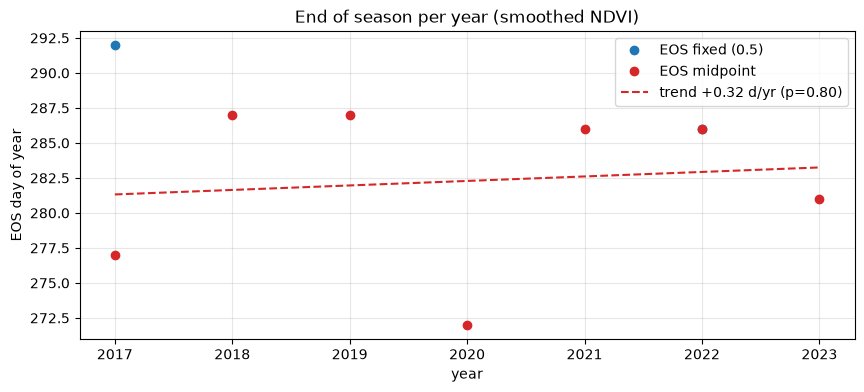

In [264]:
from scipy.stats import linregress

EOS_FIXED_THRESHOLD = 0.5
MIN_POINTS_PER_YEAR = 30   # valid 5-day values needed in a year (max ~73)

def first_crossing(post_peak, threshold):
    below = post_peak[post_peak <= threshold]
    return below.index.min() if not below.empty else pd.NaT

def eos_rows(smoothed):
    # One EOS row per calendar year of a smoothed NDVI series
    rows = []
    s_all = smoothed.dropna().sort_index()
    for year, s in s_all.groupby(s_all.index.year):
        if len(s) < MIN_POINTS_PER_YEAR:
            continue
        peak = s.idxmax()
        post_peak = s[s.index >= peak]
        peak_value = s.loc[peak]
        baseline = post_peak.min()
        midpoint = baseline + 0.5 * (peak_value - baseline)
        eos_fixed = first_crossing(post_peak, EOS_FIXED_THRESHOLD)
        eos_mid = first_crossing(post_peak, midpoint)
        rows.append({
            "year": year,
            "n_points": len(s),
            "peak_date": peak.date(),
            "peak_ndvi": round(peak_value, 3),
            "midpoint_threshold": round(midpoint, 3),
            "eos_fixed_date": eos_fixed.date() if pd.notna(eos_fixed) else None,
            "eos_fixed_doy": eos_fixed.dayofyear if pd.notna(eos_fixed) else np.nan,
            "eos_mid_date": eos_mid.date() if pd.notna(eos_mid) else None,
            "eos_mid_doy": eos_mid.dayofyear if pd.notna(eos_mid) else np.nan,
        })
    return rows

rows = [{"zone": zone, **row} for zone in ZONES for row in eos_rows(smooth(clean_by_zone["NDVI"][zone]))]
eos_table = pd.DataFrame(rows).set_index(["zone", "year"])
eos_all = eos_table.xs("all", level="zone")   # whole AOI: used below and in the trend/projection cell
display(eos_all)

# Trend line: linear regression of EOS day-of-year on year
fig, ax = plt.subplots(figsize=(10, 4))
for col, label, color in [("eos_fixed_doy", f"EOS fixed ({EOS_FIXED_THRESHOLD})", "tab:blue"),
                          ("eos_mid_doy", "EOS midpoint", "tab:red")]:
    d = eos_all[col].dropna()
    ax.plot(d.index, d.values, "o", color=color, label=label)
    if len(d) >= 3:
        fit = linregress(d.index.values, d.values)
        x = np.array([d.index.min(), d.index.max()])
        ax.plot(x, fit.intercept + fit.slope * x, "--", color=color,
                label=f"trend {fit.slope:+.2f} d/yr (p={fit.pvalue:.2f})")
        print(f"{label}: slope {fit.slope:+.2f} days/year, R2={fit.rvalue**2:.2f}, p={fit.pvalue:.3f}, n={len(d)}")
    else:
        print(f"{label}: fewer than 3 years with an EOS, no trend fitted")
ax.set_xlabel("year")
ax.set_ylabel("EOS day of year")
ax.xaxis.get_major_locator().set_params(integer=True)
ax.grid(alpha=0.3)
ax.legend()
ax.set_title("End of season per year (smoothed NDVI)")
plt.show()

### EOS trend test and short-term projection (no climate drivers)

- **Mann-Kendall / Theil-Sen:** robust check of whether a monotonic EOS trend exists. Theil-Sen gives the slope (median of pairwise slopes) with a 95 % confidence interval. Mann-Kendall gives the p-value (Kendall's tau of EOS vs. year).
- **Projection:** OLS of EOS day-of-year on year, extrapolated `FORECAST_YEARS` ahead with a **95 % prediction interval**, the range a single future year is expected to fall in. A mean-only model (no trend) is shown alongside it. If the trend is not significant, the mean ± interval is the more honest expectation.

This is a statistical extrapolation, not a phenological forecast: it ignores weather, so the intervals are wide. Climate covariates (e.g. autumn temperature) can later be added as extra columns in the OLS design matrix.

EOS fixed (0.5): fewer than 4 years with an EOS, no test/projection
EOS midpoint (n=7 years)
  Theil-Sen slope: -0.25 d/yr  (95% CI -2.50 to +5.00)
  Mann-Kendall: tau=-0.15, p=0.645 -> no significant monotonic trend
  OLS slope: +0.32 d/yr, p=0.801, R2=0.01


C:\Users\hanna\AppData\Local\Temp\ipykernel_97352\183124799.py:76: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend(fontsize=8, loc="best")


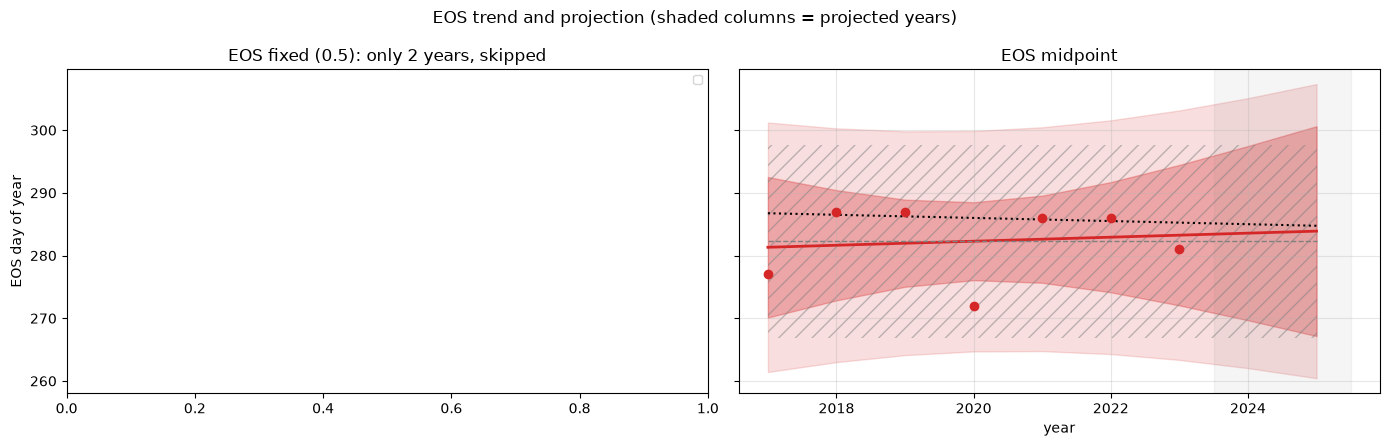

trend_doy  trend_pi_low  trend_pi_high  mean_doy  \
method       year                                                     
EOS midpoint 2024      283.6         262.0          305.1     282.3   
             2025      283.9         260.4          307.4     282.3   

                   mean_pi_low  mean_pi_high  trend_significant  trend_date  \
method       year                                                             
EOS midpoint 2024        266.9         297.7              False  2024-10-10   
             2025        266.9         297.7              False  2025-10-11   

                    mean_date  
method       year              
EOS midpoint 2024  2024-10-08  
             2025  2025-10-09

In [265]:
from datetime import date, timedelta
import statsmodels.api as sm
from scipy.stats import theilslopes, kendalltau

FORECAST_YEARS = 2
ALPHA = 0.05

proj_rows = []
methods = [("eos_fixed_doy", f"EOS fixed ({EOS_FIXED_THRESHOLD})", "tab:blue"),
           ("eos_mid_doy", "EOS midpoint", "tab:red")]
fig, axes = plt.subplots(1, len(methods), figsize=(14, 4.5), sharey=True)

for ax, (col, label, color) in zip(axes, methods):
    d = eos_all[col].dropna()
    n = len(d)
    if n < 4:
        ax.set_title(f"{label}: only {n} years, skipped")
        print(f"{label}: fewer than 4 years with an EOS, no test/projection")
        continue
    years = d.index.values.astype(float)
    y = d.values.astype(float)

    # Robust trend: Theil-Sen slope + Mann-Kendall test (Kendall's tau vs. time)
    ts_slope, ts_int, ts_lo, ts_hi = theilslopes(y, years, alpha=1 - ALPHA)
    tau, mk_p = kendalltau(years, y)

    # OLS trend model and mean-only model, years centred for numerical stability
    x0 = years.mean()
    X = sm.add_constant(years - x0)
    ols = sm.OLS(y, X).fit()
    mean_model = sm.OLS(y, np.ones((n, 1))).fit()

    future = np.arange(years.max() + 1, years.max() + 1 + FORECAST_YEARS)
    grid = np.arange(years.min(), future.max() + 1)
    pred = ols.get_prediction(sm.add_constant(grid - x0, has_constant="add")).summary_frame(alpha=ALPHA)
    pred_mean = mean_model.get_prediction(np.ones((len(grid), 1))).summary_frame(alpha=ALPHA)

    print(f"{label} (n={n} years)")
    print(f"  Theil-Sen slope: {ts_slope:+.2f} d/yr  (95% CI {ts_lo:+.2f} to {ts_hi:+.2f})")
    print(f"  Mann-Kendall: tau={tau:+.2f}, p={mk_p:.3f} -> "
          f"{'significant' if mk_p < ALPHA else 'no significant'} monotonic trend")
    print(f"  OLS slope: {ols.params[1]:+.2f} d/yr, p={ols.pvalues[1]:.3f}, R2={ols.rsquared:.2f}")

    for i, yr in enumerate(grid):
        if yr in future:
            proj_rows.append({
                "method": label, "year": int(yr),
                "trend_doy": pred["mean"].iloc[i],
                "trend_pi_low": pred["obs_ci_lower"].iloc[i],
                "trend_pi_high": pred["obs_ci_upper"].iloc[i],
                "mean_doy": pred_mean["mean"].iloc[i],
                "mean_pi_low": pred_mean["obs_ci_lower"].iloc[i],
                "mean_pi_high": pred_mean["obs_ci_upper"].iloc[i],
                "trend_significant": bool(mk_p < ALPHA),
            })

    ax.fill_between(grid, pred["obs_ci_lower"], pred["obs_ci_upper"], color=color, alpha=0.15,
                    label="OLS 95% prediction interval")
    ax.fill_between(grid, pred["mean_ci_lower"], pred["mean_ci_upper"], color=color, alpha=0.3,
                    label="OLS 95% CI of the trend")
    ax.plot(grid, pred["mean"], color=color, lw=2, label=f"OLS trend {ols.params[1]:+.2f} d/yr")
    ax.plot(grid, ts_int + ts_slope * grid, ":", color="black", lw=1.5,
            label=f"Theil-Sen {ts_slope:+.2f} d/yr (MK p={mk_p:.2f})")
    ax.plot(grid, pred_mean["mean"], "--", color="grey", lw=1, label="mean (no trend)")
    ax.fill_between(grid, pred_mean["obs_ci_lower"], pred_mean["obs_ci_upper"],
                    facecolor="none", edgecolor="grey", hatch="//", lw=0, alpha=0.5,
                    label="mean 95% prediction interval")
    ax.plot(years, y, "o", color=color, label="observed EOS")
    ax.axvspan(future.min() - 0.5, future.max() + 0.5, color="grey", alpha=0.08)
    ax.set_title(label)
    ax.set_xlabel("year")
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("EOS day of year")
axes[0].legend(fontsize=8, loc="best")
plt.suptitle("EOS trend and projection (shaded columns = projected years)")
plt.tight_layout()
plt.show()

eos_projection = pd.DataFrame(proj_rows)
if not eos_projection.empty:
    eos_projection = eos_projection.set_index(["method", "year"]).round(1)
    # Calendar dates of the central estimates, for readability
    for c in ["trend_doy", "mean_doy"]:
        eos_projection[c.replace("_doy", "_date")] = [
            date(int(yr), 1, 1) + timedelta(days=int(round(v)) - 1)
            for (_, yr), v in eos_projection[c].items()]
    display(eos_projection)

## 7b. Per-year logistic fit of the autumn transition (raw clear observations)

For each year and index, a logistic curve is fitted to the **raw clear observations** (no interpolation, no smoothing) between `FIT_WINDOW` (day of year):

`y(t) = lo + (hi - lo) / (1 + exp((t - t0) / s))`

`hi` is the summer level, `lo` the post-transition level, `t0` the 50 % point of the transition and `s` its time scale in days. NDVI and GRVI drop during yellowing (`hi > lo`). PSRI rises (`hi < lo`), and the same formula covers both directions. From the fit:
- **onset** = 20 %, **mid** = 50 % (= `t0`), **end** = 80 % of the transition, using `t = t0 + s * ln(f / (1 - f))`.

Quality columns: `n_obs` (clear dates in the window), `n_before_mid` / `n_after_mid` (observations on each side of `t0`; a date is poorly constrained if one side is nearly empty), `rmse`, and `direction_ok` (the transition goes the expected way for that index).

The fit is done for every zone (`logistic_table` is indexed by index, zone and year). The table and the plots here show the whole AOI (zone `"all"`).

n_obs     hi     lo  scale_days   rmse  n_before_mid  n_after_mid  \
index year                                                                      
NDVI  2017     17  0.764  0.354       6.688  0.030            15            2   
      2018     29  0.751  0.531       1.000  0.046            28            1   
      2019     17  0.759  0.635       1.000  0.061            16            1   
      2020     25  0.793  0.695       1.000  0.043            23            2   
      2021     26  0.756 -2.000       1.000  0.067            26            0   
      2022     28  0.795  0.283       5.044  0.085            23            5   
      2023     23  0.789  0.287      10.006  0.083            22            1   
GRVI  2017     17  0.168 -0.250       3.125  0.027            15            2   
      2018     29  0.170 -0.173       2.923  0.025            27            2   
      2019     17  0.167 -2.000       1.000  0.043            17            0   
      2020     25  0.207  0.092       1.000  0.027            24            1   
      2021     26  0.195 -2.000       1.000  0.046            26            0   
      2022     28  0.204 -0.072       1.000  0.048            22            6   
      2023     23  0.220 -0.730      12.246  0.060            23            0   
PSRI  2017     17  0.045  0.350       1.000  0.023            15            2   
      2018     29  0.029  2.000      10.058  0.021            29            0   
      2019     17  0.048  2.000       3.553  0.022            17            0   
      2020     25  0.037  0.699       1.601  0.026            25            0   
      2021     26  0.002  0.047       2.096  0.028            18            8   
      2022     28  0.022  0.151       1.000  0.047            21            7   
      2023     23  0.024  2.000       8.600  0.030            23            0   

            direction_ok  onset_doy  onset_date  mid_doy    mid_date  end_doy  \
index year                                                                      
NDVI  2017          True    272.893  2017-09-30  282.165  2017-10-09  291.437   
      2018          True    285.619  2018-10-13  287.006  2018-10-14  288.392   
      2019          True    284.588  2019-10-12  285.974  2019-10-13  287.360   
      2020          True    262.009  2020-09-18  263.395  2020-09-19  264.782   
      2021          True    288.179  2021-10-15  289.565  2021-10-17  290.951   
      2022          True    275.863  2022-10-03  282.856  2022-10-10  289.848   
      2023          True    277.716  2023-10-05  291.588  2023-10-19  305.459   
GRVI  2017          True    274.919  2017-10-02  279.251  2017-10-06  283.583   
      2018          True    281.850  2018-10-09  285.902  2018-10-13  289.955   
      2019          True    288.259  2019-10-15  289.646  2019-10-17  291.032   
      2020          True    263.259  2020-09-19  264.645  2020-09-21  266.032   
      2021          True    288.096  2021-10-15  289.483  2021-10-16  290.869   
      2022          True    278.016  2022-10-05  279.403  2022-10-06  280.789   
      2023          True    290.516  2023-10-18  307.492  2023-11-03  324.468   
PSRI  2017          True    275.789  2017-10-03  277.175  2017-10-04  278.561   
      2018          True    296.712  2018-10-24  310.655  2018-11-07  324.598   
      2019          True    290.963  2019-10-18  295.889  2019-10-23  300.815   
      2020          True    292.482  2020-10-18  294.702  2020-10-21  296.921   
      2021          True    255.435  2021-09-12  258.341  2021-09-15  261.247   
      2022          True    276.213  2022-10-03  277.600  2022-10-05  278.986   
      2023          True    305.578  2023-11-02  317.501  2023-11-14  329.423   

              end_date  
index year              
NDVI  2017  2017-10-18  
      2018  2018-10-15  
      2019  2019-10-14  
      2020  2020-09-21  
      2021  2021-10-18  
      2022  2022-10-17  
      2023  2023-11-01  
GRVI  2017  2017-10-11  
      2018  2018-10-17  
      201

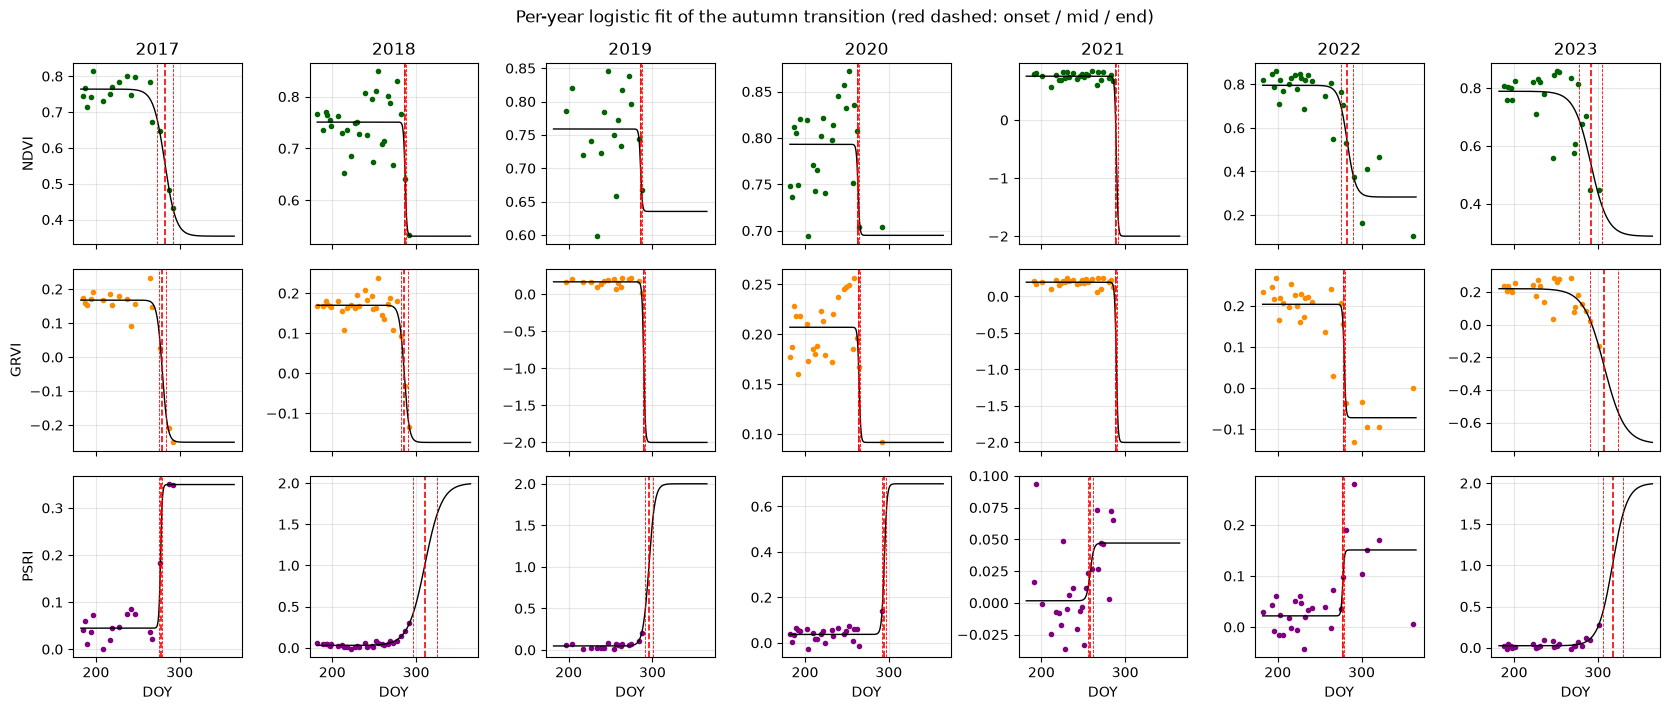

In [266]:
from datetime import date, timedelta
from scipy.optimize import curve_fit

FIT_WINDOW = (182, 365)     # day-of-year range of the autumn fit (1 Jul - 31 Dec)
MIN_OBS_PER_YEAR = 6        # clear observations in the window required for a fit
TRANSITION_FRACTIONS = {"onset": 0.2, "mid": 0.5, "end": 0.8}
EXPECT_DECREASE = {"NDVI": True, "GRVI": True, "PSRI": False}   # PSRI rises with yellowing
INDEX_COLORS = {"NDVI": "darkgreen", "GRVI": "darkorange", "PSRI": "purple"}

def logistic(t, hi, lo, t0, s):
    # hi before the transition, lo after; t0 = 50 % point (DOY), s = time scale (days)
    return lo + (hi - lo) / (1 + np.exp((t - t0) / s))

def fit_logistic(doy, y):
    split = np.median(doy)
    p0 = [np.median(y[doy <= split]), np.median(y[doy > split]), 280, 7]
    bounds = ([-2, -2, FIT_WINDOW[0], 1], [2, 2, FIT_WINDOW[1], 40])
    popt, _ = curve_fit(logistic, doy, y, p0=p0, bounds=bounds, maxfev=20000)
    return popt

def logistic_rows(name, series, zone="all"):
    # Per-year logistic fit of one index's clear observations; returns the table rows and {year: (doy, y, popt)}
    rows, fits = [], {}
    ser = series.dropna()
    for year, s in ser.groupby(ser.index.year):
        doy = s.index.dayofyear.values.astype(float)
        sel = (doy >= FIT_WINDOW[0]) & (doy <= FIT_WINDOW[1])
        doy, y = doy[sel], s.values[sel]
        if len(y) == 0:
            continue
        row = {"index": name, "zone": zone, "year": year, "n_obs": len(y)}
        popt = None
        if len(y) >= MIN_OBS_PER_YEAR:
            try:
                popt = fit_logistic(doy, y)
            except RuntimeError:
                print(f"{name} {zone} {year}: fit did not converge")
        if popt is not None:
            hi, lo, t0, sc = popt
            row.update({
                "hi": hi, "lo": lo, "scale_days": sc,
                "rmse": np.sqrt(np.mean((logistic(doy, *popt) - y) ** 2)),
                "n_before_mid": int((doy < t0).sum()),
                "n_after_mid": int((doy >= t0).sum()),
                "direction_ok": bool((hi > lo) == EXPECT_DECREASE[name]),
            })
            for label, f in TRANSITION_FRACTIONS.items():
                d = t0 + sc * np.log(f / (1 - f))
                row[f"{label}_doy"] = d
                row[f"{label}_date"] = date(int(year), 1, 1) + timedelta(days=int(round(d)) - 1)
        fits[year] = (doy, y, popt)
        rows.append(row)
    return rows, fits

index_series = {name: by_zone["all"] for name, by_zone in clean_by_zone.items()}

rows, fits = [], {}
for name in index_series:
    for zone in ZONES:
        zone_rows, zone_fits = logistic_rows(name, clean_by_zone[name][zone], zone)
        rows += zone_rows
        if zone == "all":
            fits.update({(name, year): fit for year, fit in zone_fits.items()})

logistic_table = pd.DataFrame(rows).set_index(["index", "zone", "year"]).round(3)
display(logistic_table.xs("all", level="zone"))

# One panel per index (rows) and year (columns): clear observations, fitted curve, onset/mid/end
fit_years = sorted({yr for _, yr in fits})
if fit_years:
    tt = np.linspace(*FIT_WINDOW, 300)
    fig, axes = plt.subplots(len(index_series), len(fit_years), squeeze=False, sharex=True,
                             figsize=(2.4 * len(fit_years), 2.4 * len(index_series)))
    for i, name in enumerate(index_series):
        for j, year in enumerate(fit_years):
            ax = axes[i, j]
            if (name, year) in fits:
                doy, y, popt = fits[(name, year)]
                ax.plot(doy, y, "o", ms=3, color=INDEX_COLORS[name])
                if popt is not None:
                    ax.plot(tt, logistic(tt, *popt), color="black", lw=1)
                    for label, f in TRANSITION_FRACTIONS.items():
                        d = popt[2] + popt[3] * np.log(f / (1 - f))
                        ax.axvline(d, color="red", lw=1.2 if label == "mid" else 0.6, ls="--")
            if i == 0:
                ax.set_title(str(year))
            if j == 0:
                ax.set_ylabel(name)
            if i == len(index_series) - 1:
                ax.set_xlabel("DOY")
            ax.grid(alpha=0.3)
    plt.suptitle("Per-year logistic fit of the autumn transition (red dashed: onset / mid / end)")
    plt.tight_layout()
    plt.show()

## 7d. Phenology vs topography (elevation band × aspect)

Every zone has its own clear-date series: the same quality filter as `"all"`, with that zone's SCL shares and valid fraction. It also has its own per-year logistic fit (7b) and EOS (7a). Here these dates are related to the zone's mean elevation and aspect class.
- Only logistic fits with `direction_ok` and at least `MIN_OBS_SIDE` observations on each side of `t0` are used.
- **Plot:** transition DOY against elevation band, with one line per aspect (mean over years ± standard deviation; points are single zone-years). There is one panel for each index's logistic mid point, plus one for the NDVI EOS midpoint. The fixed-threshold EOS is left out because a fixed NDVI level is confounded by different NDVI levels between zones.
- **Model** (OLS, one per panel): `doy ~ elev_100m + C(aspect) + C(year)`. `elev_100m` is the zone's mean elevation in units of 100 m, so its coefficient is in **days per 100 m**. The aspect coefficient, with south as the reference, is the **north − south difference** in days. `C(year)` absorbs year-to-year weather, so both effects are estimated within years. The intervals are 95 % CIs.

Caveats:
- Zones in the same year share weather and clouds, so the CIs are somewhat optimistic.
- North slopes lose more autumn dates to the SCL dark/topographic-shadow class (2, not in `SCL_KEEP`). Check `mean_n_obs_*` and `autumn_dark_fraction` in the first table: a zone with few late-season observations has a poorly constrained transition.
- Aspect also changes illumination. NDVI and GRVI are ratios and fairly robust, but PSRI on north slopes in Nov/Dec (low sun) is more affected, so interpret its aspect effect with care.

In [ ]:
import statsmodels.formula.api as smf

MIN_OBS_SIDE = 2   # clear observations required on each side of the logistic mid point

# Observation coverage per zone: mean clear dates in FIT_WINDOW per index and mean autumn share of SCL class 2
autumn = stats_all[stats_all.index.dayofyear >= FIT_WINDOW[0]]
coverage = (zone_table[["elev_band", "aspect", "n_pixels", "elev_mean", "slope_mean", "northness_mean"]]
            .join(logistic_table.groupby(level=["zone", "index"]).n_obs.mean().unstack().add_prefix("mean_n_obs_"))
            .join(autumn.groupby("zone").scl_dark_fraction.mean().rename("autumn_dark_fraction")))
display(coverage.round(2))

# Per-zone, per-year dates with the zone attributes ("all" is left out by the inner join)
zone_attrs = zone_table.drop(index="all")[["elev_band", "aspect", "elev_mean"]]
fits_ok = logistic_table.reset_index().join(zone_attrs, on="zone", how="inner")
fits_ok = fits_ok[fits_ok.direction_ok.eq(True) & (fits_ok.n_before_mid >= MIN_OBS_SIDE)
                  & (fits_ok.n_after_mid >= MIN_OBS_SIDE)]
eos_zones = eos_table.reset_index().join(zone_attrs, on="zone", how="inner")

# (label, data, DOY column): one plot panel and one model each
responses = [(f"{name} logistic mid", fits_ok[fits_ok["index"] == name], "mid_doy") for name in INDEX_COLORS]
responses.append(("NDVI EOS midpoint", eos_zones, "eos_mid_doy"))

fig, axes = plt.subplots(1, len(responses), figsize=(4 * len(responses), 4), sharex=True)
for ax, (label, data, col) in zip(axes, responses):
    for asp, color in ASPECT_COLORS.items():
        d = data[data.aspect == asp].dropna(subset=[col])
        if d.empty:
            continue
        shift = ELEV_STEP / 2 + {"N": -0.08, "S": 0.08, "flat": 0}[asp] * ELEV_STEP   # band centre, dodged
        ax.scatter(d.elev_band + shift, d[col], s=8, color=color, alpha=0.3)
        g = d.groupby("elev_band")[col].agg(["mean", "std"])
        ax.errorbar(g.index + shift, g["mean"], yerr=g["std"].fillna(0), fmt="o-", color=color, capsize=3,
                    label=asp)
    ax.set_title(label)
    ax.set_xlabel("elevation band centre (m)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("day of year")
axes[0].legend(title="aspect")
plt.suptitle("Autumn transition vs elevation and aspect (points: zone-years, lines: mean ± sd over years)")
plt.tight_layout()
plt.show()

NS_TERM = "C(aspect, Treatment('S'))[T.N]"

def topo_model(data, col):
    # OLS of a DOY column on zone elevation (per 100 m), aspect (south = reference) and year fixed effects
    d = data.dropna(subset=[col]).assign(elev_100m=lambda x: x.elev_mean / 100)
    if (not {"N", "S"} <= set(d.aspect) or d.elev_band.nunique() < 2
            or len(d) < d.year.nunique() + d.aspect.nunique() + 3):
        return None
    return smf.ols(f"{col} ~ elev_100m + C(aspect, Treatment('S')) + C(year)", data=d).fit()

rows = []
for label, data, col in responses:
    fit = topo_model(data, col)
    if fit is None:
        print(f"{label}: too few zone-years (needs N and S zones and >= 2 elevation bands), no model")
        continue
    ci = fit.conf_int(ALPHA)
    rows.append({
        "response": label, "n_zone_years": int(fit.nobs), "n_zones": data.zone.nunique(),
        "days_per_100m": fit.params["elev_100m"],
        "elev_ci_low": ci.loc["elev_100m", 0], "elev_ci_high": ci.loc["elev_100m", 1],
        "elev_p": fit.pvalues["elev_100m"],
        "north_minus_south_days": fit.params[NS_TERM],
        "ns_ci_low": ci.loc[NS_TERM, 0], "ns_ci_high": ci.loc[NS_TERM, 1], "ns_p": fit.pvalues[NS_TERM],
        "r2": fit.rsquared,
    })
    print(f"{label}: {fit.params['elev_100m']:+.2f} d per 100 m "
          f"(95% CI {ci.loc['elev_100m', 0]:+.2f} to {ci.loc['elev_100m', 1]:+.2f}), "
          f"north - south {fit.params[NS_TERM]:+.1f} d ({ci.loc[NS_TERM, 0]:+.1f} to {ci.loc[NS_TERM, 1]:+.1f}), "
          f"n={int(fit.nobs)}")

topo_effects = pd.DataFrame(rows).set_index("response").round(3) if rows else pd.DataFrame()
display(topo_effects)

## 7c. Trend / seasonal / remainder decomposition (STL)

Splits each index into a long-term **trend**, a repeating yearly **seasonal** cycle and the **remainder** (noise, clouds the mask missed, disturbances). Uses robust STL on a regular 5-day grid, so outliers are down-weighted instead of distorting the trend. Runs on the whole AOI (zone `"all"`).

**Note:** a seasonal cycle can only be separated from the trend with at least two full years of data, so set `START`/`END` to span several years (currently 2017-2026).

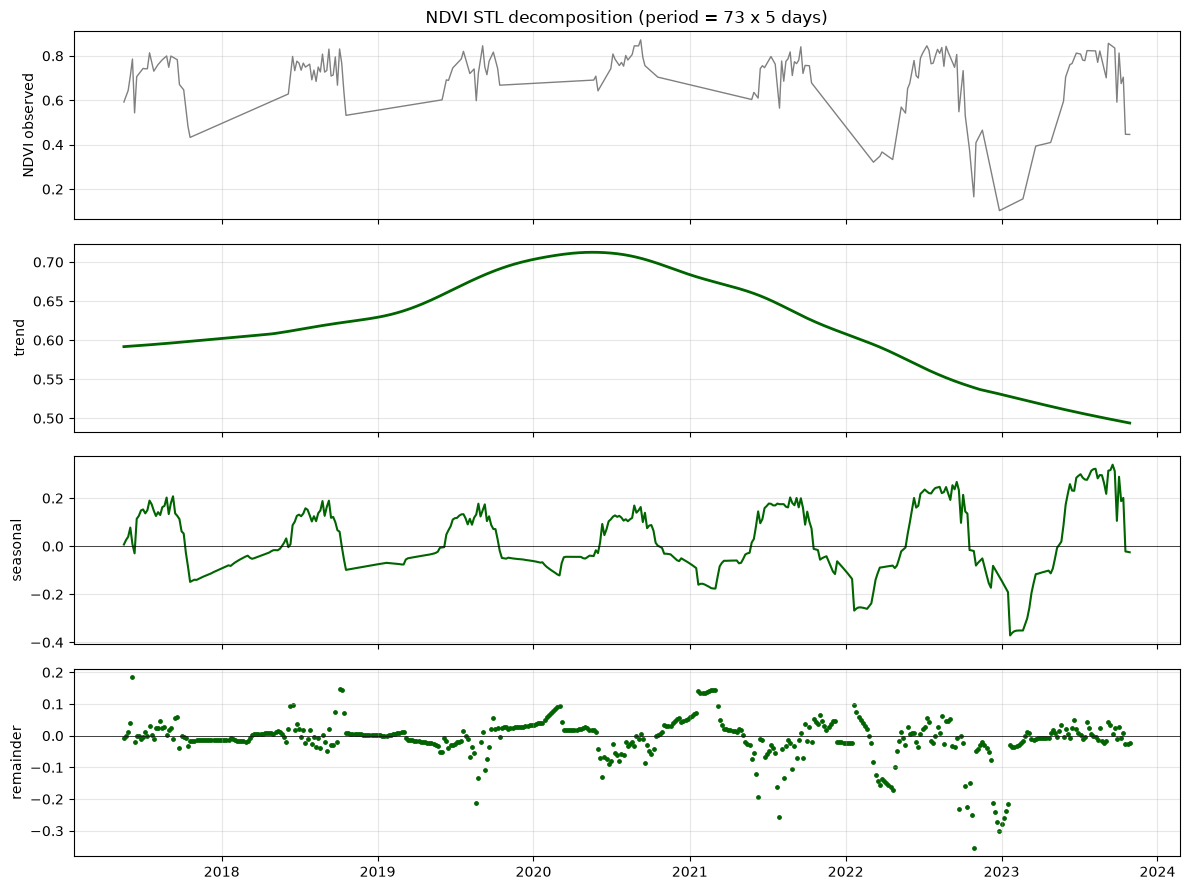

NDVI trend slope: -0.0152 per year | seasonal amplitude: 0.710 | remainder std: 0.065


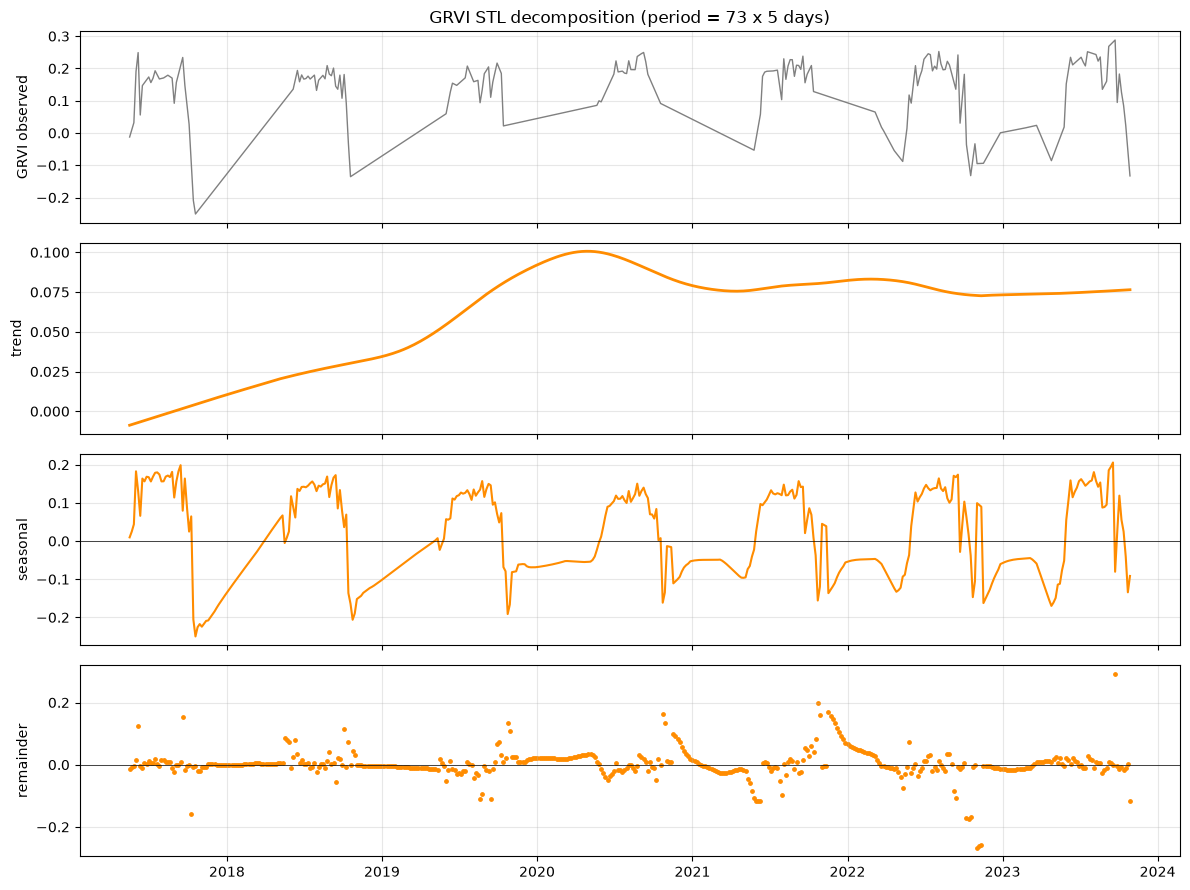

GRVI trend slope: +0.0121 per year | seasonal amplitude: 0.456 | remainder std: 0.049


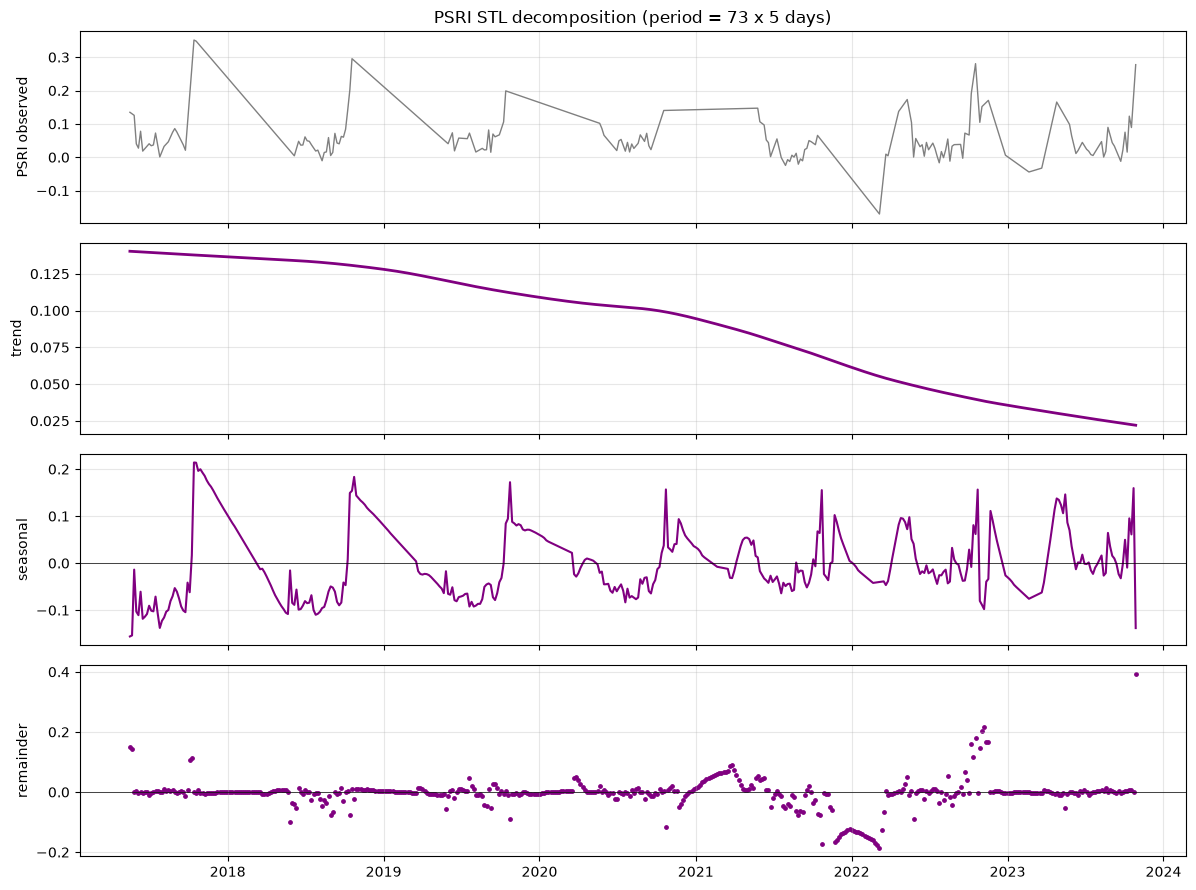

PSRI trend slope: -0.0203 per year | seasonal amplitude: 0.370 | remainder std: 0.051


In [267]:
from statsmodels.tsa.seasonal import STL

STEP_DAYS = 5
PERIOD = int(round(365.25 / STEP_DAYS))  # observations per year on the regular grid (73)

def stl_decompose(series, name):
    # STL needs a gap-free, regularly spaced series: resample, trim to the observed span, interpolate gaps
    s = series.resample(f"{STEP_DAYS}D").mean()
    s = s.loc[s.first_valid_index():s.last_valid_index()].interpolate(method="time")
    if len(s) < 2 * PERIOD:
        print(f"{name}: {len(s) * STEP_DAYS / 365.25:.1f} years of data; STL needs at least 2 full years. "
              "Extend START/END to separate season from trend.")
        return None
    res = STL(s, period=PERIOD, robust=True).fit()
    return pd.DataFrame({"observed": s, "trend": res.trend,
                         "seasonal": res.seasonal, "remainder": res.resid})

decomp_ndvi = stl_decompose(df_clean["ndvi_median"], "NDVI")
decomp_grvi = stl_decompose(df_grvi_clean["grvi_median"], "GRVI")
decomp_psri = stl_decompose(df_psri_clean["psri_median"], "PSRI")

for name, dec, color in [("NDVI", decomp_ndvi, "darkgreen"), ("GRVI", decomp_grvi, "darkorange"),
                         ("PSRI", decomp_psri, "purple")]:
    if dec is None:
        continue
    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    axes[0].plot(dec.index, dec.observed, color="grey", lw=1)
    axes[0].set_ylabel(f"{name} observed")
    axes[1].plot(dec.index, dec.trend, color=color, lw=2)
    axes[1].set_ylabel("trend")
    axes[2].plot(dec.index, dec.seasonal, color=color, lw=1.5)
    axes[2].axhline(0, color="black", lw=0.5)
    axes[2].set_ylabel("seasonal")
    axes[3].scatter(dec.index, dec.remainder, s=6, color=color)
    axes[3].axhline(0, color="black", lw=0.5)
    axes[3].set_ylabel("remainder")
    for a in axes:
        a.grid(alpha=0.3)
    axes[0].set_title(f"{name} STL decomposition (period = {PERIOD} x {STEP_DAYS} days)")
    plt.tight_layout()
    plt.show()

    # Linear slope of the trend component, per year
    t_years = (dec.index - dec.index[0]).days / 365.25
    slope = np.polyfit(t_years, dec.trend.values, 1)[0]
    print(f"{name} trend slope: {slope:+.4f} per year | seasonal amplitude: "
          f"{dec.seasonal.max() - dec.seasonal.min():.3f} | remainder std: {dec.remainder.std():.3f}")

## 8. Export

In [268]:
# One results folder per AOI (OUT_DIR, section 1), so the AOIs don't overwrite each other
OUT_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT_DIR / "ndvi_timeseries_all_dates.csv")
df_clean.to_csv(OUT_DIR / "ndvi_timeseries_clean.csv")
monthly.to_frame("ndvi_monthly_median").to_csv(OUT_DIR / "ndvi_monthly.csv")
# Zone analysis: per-zone and per-year dates (zone "all" = whole AOI), zone attributes, topography effects (7d)
eos_table.to_csv(OUT_DIR / "eos_by_zone.csv")
logistic_table.to_csv(OUT_DIR / "logistic_by_zone.csv")
zone_table.to_csv(OUT_DIR / "zones.csv")
topo_effects.to_csv(OUT_DIR / "topography_effects.csv")
print(f"Results written to {OUT_DIR}")
# Per-date statistics of all indices and zones are also cached per year in CACHE_DIR

## Next steps / extensions

- per Pixel Analyse anstatt per Polygon
- ~~nach Elevation und Aspect~~ erledigt: Zonen in Abschnitt 3 (`zone_layers`), Auswertung in 7d
- validieren mit Ground Truth data
- Klimadaten hinzufügen: Recherche welche relevant sind, dann Daten finden, dann Implementierung
-andere Indexe hinzufügen